# EDA

In [2]:
import numpy as np
from collections import Counter
from datasets import load_dataset
import pandas as pd

/Users/ricostadeli/Documents/HSG/DeepLearning/R-L-Net/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
ds = load_dataset("blanchon/EuroSAT_MSI")
train_ds = ds.get("train", None)
val_ds = ds.get("validation", None) or ds.get("val", None)
test_ds = ds.get("test", None)

## EuroSAT Dataset


In [10]:
print("Dataset length:", len(train_ds))
sample = train_ds[0]

print("Keys:", sample.keys())
print("Label:", sample["label"])

Dataset length: 16200
Keys: dict_keys(['image', 'label', 'filename'])
Label: 0


In [11]:
img = train_ds[0]["image"]  # list of np arrays / bands
arr = np.stack(img)  # stack into HWC format

print("Array shape:", arr.shape)

Array shape: (64, 64, 13)


## Rescisc45 Dataset

In [3]:
ds = load_dataset("timm/resisc45")
splits = {}
for split in ds:
    labels = ds[split]["label"]
    splits[split] = Counter(labels)

# Turn counters into DataFrame for easier plotting
df = pd.DataFrame(splits).fillna(0).astype(int)

# Add class names
classes = ds["train"].features["label"].names
df.index = classes

print(df)

                       train  validation  test
airplane                 408         139   153
airport                  410         172   118
baseball_diamond         437         145   118
basketball_court         429         128   143
beach                    426         140   134
bridge                   417         153   130
chaparral                435         150   115
church                   422         135   143
circular_farmland        401         140   159
cloud                    400         178   122
commercial_area          391         145   164
dense_residential        410         159   131
desert                   404         152   144
forest                   432         131   137
freeway                  421         144   135
golf_course              407         131   162
ground_track_field       434         136   130
harbor                   422         124   154
industrial_area          433         127   140
intersection             427         143   130
island       

Class Distribution Plot

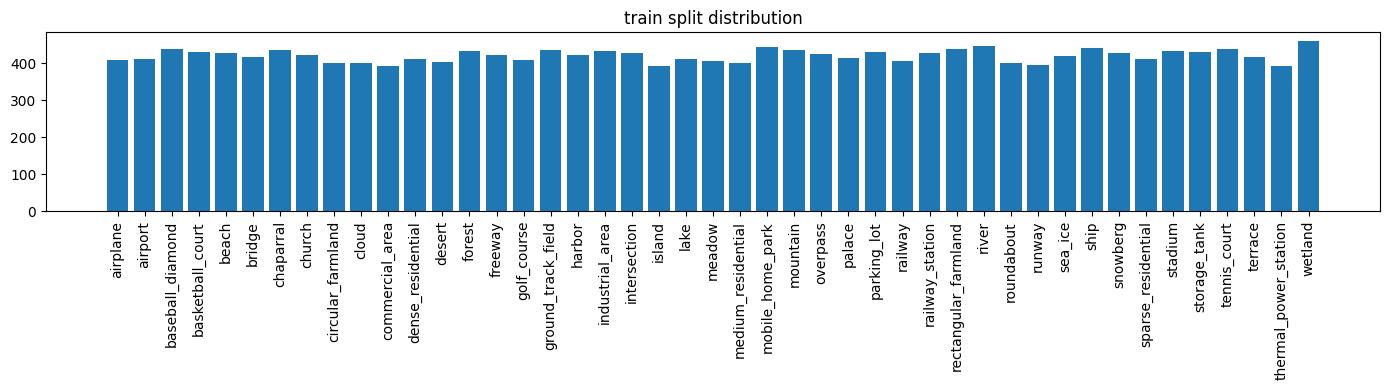

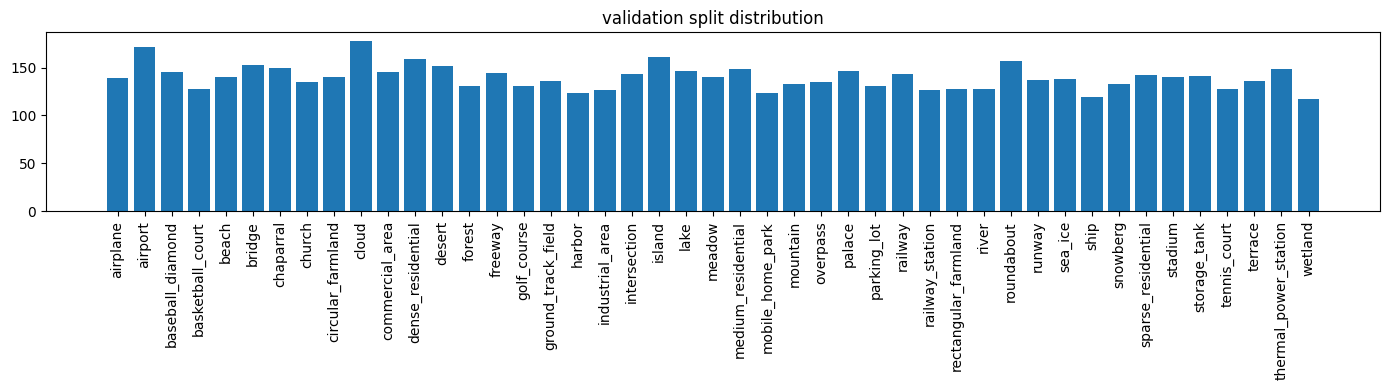

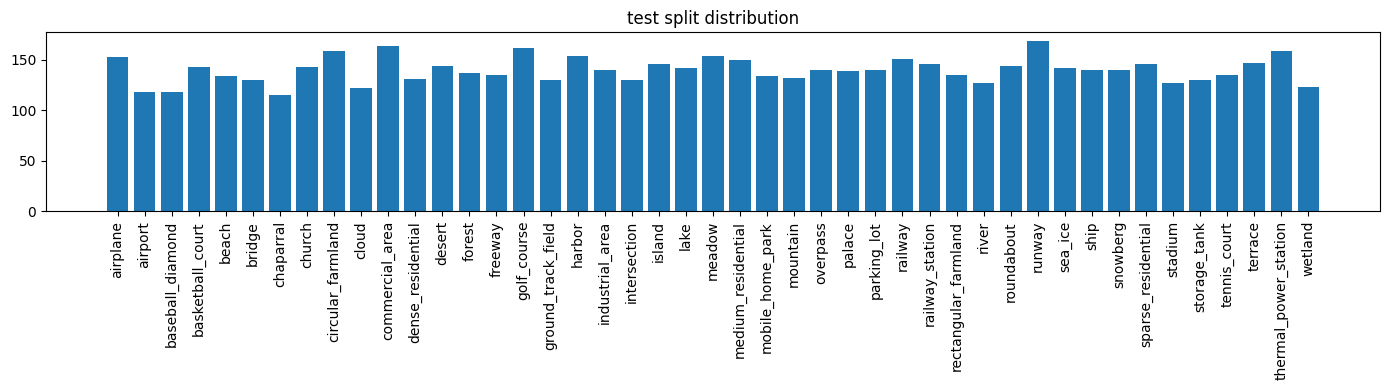

In [4]:
import matplotlib.pyplot as plt
for split in splits:
    plt.figure(figsize=(14,4))
    plt.bar(df.index, df[split])
    plt.title(f"{split} split distribution")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

In [13]:
print("Dataset length:", len(train_ds))
sample = train_ds[0]

print("Keys:", sample.keys())
print("Image:", sample["image"])
print("Size:", sample["image"].size)  # (width, height)
print("Label:", sample["label"])

Dataset length: 18900
Keys: dict_keys(['image', 'label', 'image_id'])
Image: <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256 at 0x14AB09A60>
Size: (256, 256)
Label: 32


In [14]:
img = train_ds[0]["image"]  # PIL image
arr = np.array(img)

print("PIL mode:", img.mode)              # e.g. "RGB"
print("Array shape:", arr.shape)          # e.g. (256, 256, 3)

PIL mode: RGB
Array shape: (256, 256, 3)
